# SentraGrade: ViT-B/16 and DINOv2 ViT-S/14 on the leakage-corrected split

Both transformers are trained the same way as in the earlier ViT and DINOv2 notebooks: **frozen pretrained backbone + a trainable linear head** (a linear probe). The only change is the data split. This notebook uses exactly the same split code as `leakage_split_resnet50.ipynb`, so the ResNet50, ViT and DINOv2 numbers are directly comparable.

| Backbone | Pretrained weights | Embedding | Head |
|---|---|---|---|
| `vit_b16` | ViT-B/16, ImageNet-21k (the Google checkpoint the ViT notebook used, `google/vit-base-patch16-224-in21k`; loaded here through timm as `vit_base_patch16_224.orig_in21k`) | 768-d CLS token | Linear 768 → 5 |
| `dinov2_s14` | DINOv2 ViT-S/14, LVD-142M (`vit_small_patch14_dinov2.lvd142m`, 224 px input) | 384-d CLS token | Linear 384 → 5 |

How it runs: every image goes through each frozen backbone **once** and the embeddings are cached (the slow part, ~5–10 min on a T4). Then for each protocol (`old`, `corrected`) and each of the 6 leave-one-class-out folds, a linear head is trained on the cached training embeddings with class weights and early stopping on val accuracy (seconds per fold). Scores: MSP, energy, and prototype distance (distance to the nearest class mean of training embeddings), with the threshold set at the 95th percentile of val and the reported numbers on the held-out test days.

**Kaggle setup:** Add Input → `sentragrade-data` (must contain `spoilage_labels.csv`). Turn on **GPU T4** and **Internet** (the backbone weights download from Hugging Face). Then Save Version → Save & Run All. Optional: also add the output of the leakage notebook, and the last section will put ResNet50 next to the two transformers in one table.

In [1]:
import os, json, time, random, shutil, glob
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
try:
    import timm
except ImportError:
    os.system("pip install -q timm"); import timm

# ---------------- config ----------------
SEED = 42
CLASSES = ["Banana", "Carrot", "Guava", "Indian_Gooseberry", "Mango", "Tomato"]
PROTOCOLS = ["old", "corrected"]   # old = original day-grouped folds (reported on val); corrected = leakage-corrected
FOLDS = list(range(6))
BACKBONES = {
    "vit_b16":    dict(timm_name="vit_base_patch16_224.orig_in21k", kwargs={}),
    "dinov2_s14": dict(timm_name="vit_small_patch14_dinov2.lvd142m", kwargs={"img_size": 224}),
}
SPLIT_MODE = "stage_matched"       # must match the leakage notebook
SPLIT_DIRECTION = "forward"
TRAIN_FRAC = 0.60
BUFFER_DAYS = 1
SESSION_GAP_MIN = 5
HEAD_EPOCHS, HEAD_PATIENCE, HEAD_BATCH = 200, 20, 256
HEAD_LR, HEAD_WD = 1e-3, 1e-4      # same optimiser and learning rate as the original ViT linear probe
N_BOOT = 1000
QUICK = False                      # True = 2 folds, small subsets (smoke test only)

def find_data_root():
    env = os.environ.get("SENTRAGRADE_DATA_ROOT")
    if env:
        return Path(env)
    hits = glob.glob("/kaggle/input/**/manifest_full.csv", recursive=True)
    if hits:
        return Path(hits[0]).parent
    return Path("~/sentragrade_data").expanduser()

DATA_ROOT = find_data_root()

def find_spoil_csv():
    env = os.environ.get("SPOIL_CSV")
    if env:
        return Path(env)
    hits = glob.glob("/kaggle/input/**/spoilage_labels.csv", recursive=True) + glob.glob(str(DATA_ROOT / "**/spoilage_labels.csv"), recursive=True)
    for h in hits + ["kaggle/spoilage_labels.csv", "../kaggle/spoilage_labels.csv"]:
        if os.path.exists(h):
            return Path(h)
    return None
SPOIL_CSV = find_spoil_csv()

OUT = Path("/kaggle/working/sentragrade_transformers") if Path("/kaggle/working").exists() else Path("outputs/sentragrade_transformers")
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
if QUICK:
    FOLDS, N_BOOT = [0, 3], 50
print("data root:", DATA_ROOT, "| spoilage labels:", SPOIL_CSV, "| split:", SPLIT_MODE, SPLIT_DIRECTION, "| device:", DEVICE, "| output:", OUT)
assert (DATA_ROOT / "manifest_full.csv").exists(), "manifest_full.csv not found: attach the sentragrade-data dataset"
assert SPLIT_MODE == "time_blocked" or SPOIL_CSV is not None, "spoilage_labels.csv not found: add it to the dataset"

data root: /kaggle/input/datasets/riteesh23f3002667/sentragrade-data/sentragrade_data | spoilage labels: /kaggle/input/datasets/riteesh23f3002667/sentragrade-data/spoilage_labels.csv | split: stage_matched forward | device: cuda | output: /kaggle/working/sentragrade_transformers


## 1. Splits (same code as the leakage notebook)

In [2]:
man = pd.read_csv(DATA_ROOT / "manifest_full.csv", dtype={"date": str, "time": str})
man["path"] = [str(DATA_ROOT / "resized" / c / f) for c, f in zip(man.class_name, man.filename)]
missing = [p for p in man.path if not os.path.exists(p)]
assert not missing, f"{len(missing)} images missing, e.g. {missing[:3]}"
if SPOIL_CSV is not None:
    sp = pd.read_csv(SPOIL_CSV)
    man = man.drop(columns=[c for c in ["spoil_status"] if c in man.columns]).merge(sp, on=["class_name", "filename"], how="left")
    assert man.spoil_status.notna().all(), f"{man.spoil_status.isna().sum()} images have no spoilage label"
else:
    man["spoil_status"] = "unknown"

# capture sessions: a burst of ~17 photos; used as the resampling unit for the bootstrap
man["ts"] = pd.to_datetime(man.date + man.time.str.zfill(6), format="%Y%m%d%H%M%S")
man = man.sort_values(["class_name", "ts"]).reset_index(drop=True)
gap = man.groupby("class_name").ts.diff() > pd.Timedelta(minutes=SESSION_GAP_MIN)
man["session"] = man.class_name + "_" + gap.groupby(man.class_name).cumsum().astype(str)
key = dict(zip(man.class_name + "/" + man.filename, man.session))
spoil_key = dict(zip(man.class_name + "/" + man.filename, man.spoil_status))

def blocked_split(d):
    # whole capture days, in time order: train block, buffer day(s) dropped, then val and test blocks.
    # Small blocks (a stage with only 2-4 days) degrade gracefully: the buffer is skipped when it would
    # leave fewer than 2 days, and 2 days give train + test with no val.
    days = sorted(d.date.unique(), reverse=(SPLIT_DIRECTION == "reverse"))
    if len(days) == 1:
        return days, [], [], []
    if len(days) == 2:
        return days[:1], [], [], days[1:]
    n = d.groupby("date").size().reindex(days).values
    cum = np.cumsum(n) / n.sum()
    n_tr = int(np.clip((cum <= TRAIN_FRAC).sum(), 1, len(days) - 2))
    buf_n = BUFFER_DAYS if len(days) - n_tr - BUFFER_DAYS >= 2 else 0
    rest = days[n_tr + buf_n:]
    k = max(1, len(rest) // 2)
    return days[:n_tr], days[n_tr:n_tr + buf_n], rest[:k], rest[k:]

def split_class(d):
    if SPLIT_MODE == "time_blocked":
        return blocked_split(d)
    # stage-matched: every capture day is all fresh or all spoiled (checked), block each stage separately
    stage_of_day = d.groupby("date").spoil_status.agg(lambda x: x.mode().iloc[0])
    mixed = d.groupby("date").spoil_status.nunique()
    assert (mixed == 1).all(), f"{d.class_name.iloc[0]}: some days mix fresh and spoiled images"
    out = [[], [], [], []]
    for st in sorted(stage_of_day.unique()):
        part = blocked_split(d[d.date.isin(stage_of_day[stage_of_day == st].index)])
        for i in range(4):
            out[i] += list(part[i])
    return tuple(sorted(x) for x in out)

split_days, rows = {}, []
for c, d in man.groupby("class_name"):
    tr, buf, va, te = split_class(d)
    assert va and te, f"{c}: split left no val or no test days"
    split_days[c] = dict(train=tr, buffer=buf, val=va, test=te)
    fr = lambda days: f"{(d.date.isin(days) & (d.spoil_status == 'Not_spoiled')).sum()}/{(d.date.isin(days) & (d.spoil_status == 'Spoiled')).sum()}"
    rows.append({"class": c, "days": d.date.nunique(),
                 "train_days": ",".join(tr), "buffer": ",".join(buf),
                 "val_days": ",".join(va), "test_days": ",".join(te),
                 "train_n": d.date.isin(tr).sum(), "val_n": d.date.isin(va).sum(),
                 "test_n": d.date.isin(te).sum(), "dropped_n": d.date.isin(buf).sum(),
                 "train_fresh/spoiled": fr(tr), "val_fresh/spoiled": fr(va), "test_fresh/spoiled": fr(te)})
corrected_table = pd.DataFrame(rows)
display(corrected_table)
corrected_table.to_csv(OUT / "corrected_split_days.csv", index=False)

def tag(df):
    df = df.copy()
    df["path"] = [str(DATA_ROOT / "resized" / c / f) for c, f in zip(df.class_name, df.filename)]
    df["session"] = (df.class_name + "/" + df.filename).map(key)
    df["spoil_status"] = (df.class_name + "/" + df.filename).map(spoil_key)
    return df

def get_fold(protocol, k):
    held = CLASSES[k]
    known = [c for c in CLASSES if c != held]
    label_map = {c: i for i, c in enumerate(sorted(known))}
    ood = man[man.class_name == held]
    if protocol == "old":
        tr = tag(pd.read_csv(DATA_ROOT / "folds" / f"fold{k}_train.csv", dtype={"date": str}))
        va = tag(pd.read_csv(DATA_ROOT / "folds" / f"fold{k}_val.csv", dtype={"date": str}))
        te = va                    # the paper reports on val: reproduce that exactly
    else:
        kn = man[man.class_name != held]
        pick = lambda part: pd.concat([kn[(kn.class_name == c) & kn.date.isin(split_days[c][part])] for c in known])
        tr, va, te = pick("train"), pick("val"), pick("test")
        # checks: no capture day shared between blocks, buffer gap respected, test unseen
        for c in known:
            s = split_days[c]
            assert not (set(s["train"]) & set(s["val"])) and not (set(s["train"]) & set(s["test"])) and not (set(s["val"]) & set(s["test"]))
        assert set(tr.path).isdisjoint(te.path) and set(va.path).isdisjoint(te.path) and set(tr.path).isdisjoint(va.path)
    assert held not in set(tr.class_name) | set(va.class_name) | set(te.class_name)
    if QUICK:
        tr = tr.groupby("class_name").head(40); va = va.groupby("class_name").head(20)
        te = te.groupby("class_name").head(20) if protocol == "corrected" else va; ood = ood.head(60)
    return dict(train=tr, val=va, test=te, ood=ood, label_map=label_map, held=held)

summary = []
for p in PROTOCOLS:
    for k in FOLDS:
        f = get_fold(p, k)
        summary.append({"protocol": p, "fold": k, "held_out": f["held"], "train": len(f["train"]),
                        "val": len(f["val"]), "test": len(f["test"]) if p == "corrected" else "= val", "ood": len(f["ood"])})
display(pd.DataFrame(summary))

,class,days,train_days,buffer,val_days,test_days,train_n,val_n,test_n,dropped_n,train_fresh/spoiled,val_fresh/spoiled,test_fresh/spoiled
0,Banana,7,"20250911,20250915,20250916",,"20250912,20250917","20250913,20250918",119,102,102,0,51/68,51/51,51/51
1,Carrot,9,"20250725,20250728,20250729,20250730,20250731",20250801,20250802,"20250726,20250804",255,51,102,50,51/204,0/51,51/51
2,Guava,10,"20250625,20250626,20250630,20250701,20250702",20250703,"20250627,20250704","20250628,20250705",255,102,102,51,102/153,51/51,51/51
3,Indian_Gooseberry,30,"20250723,20250724,20250725,20250726,20250728,2...","20250804,20250901","20250805,20250806,20250807,20250902,20250903","20250808,20250809,20250811,20250812,20250904,2...",833,238,238,102,527/306,136/102,170/68
4,Mango,8,"20250920,20250922,20250923,20250929",,"20250924,20250930","20250926,20251003",187,103,102,0,153/34,52/51,51/51
5,Tomato,48,"20250723,20250724,20250725,20250726,20250728,2...",20250901,"20250902,20250903,20250904,20250908,20250909,2...","20250915,20250916,20250917,20250918,20250919,2...",1275,459,459,51,1207/68,408/51,408/51


,protocol,fold,held_out,train,val,test,ood
0,old,0,Banana,3978,1037,= val,323
1,old,1,Carrot,3843,1037,= val,458
2,old,2,Guava,3791,1037,= val,510
3,old,3,Indian_Gooseberry,3077,850,= val,1411
4,old,4,Mango,3892,1054,= val,392
5,old,5,Tomato,2414,680,= val,2244
6,corrected,0,Banana,2805,953,1003,323
7,corrected,1,Carrot,2669,1004,1003,458
8,corrected,2,Guava,2669,953,1003,510
9,corrected,3,Indian_Gooseberry,2091,817,867,1411


## 2. Embed every image once with each frozen backbone

In [3]:
need = set()
for p in PROTOCOLS:
    for k in FOLDS:
        f = get_fold(p, k)
        for part in ["train", "val", "test", "ood"]:
            need |= set(f[part].path)
need = sorted(need)
print(len(need), "images to embed")

class PathDS(Dataset):
    def __init__(self, paths, tf): self.paths, self.tf = paths, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return self.tf(Image.open(self.paths[i]).convert("RGB"))

def embed_all(name, spec):
    cache = OUT / f"embeddings_{name}.pt"
    if cache.exists():
        d = torch.load(cache)
        if set(need) <= set(d["paths"]):
            print(name, "loaded from cache"); return d
    model = timm.create_model(spec["timm_name"], pretrained=True, num_classes=0, **spec["kwargs"]).to(DEVICE).eval()
    cfg = timm.data.resolve_data_config({}, model=model)
    tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                             transforms.ToTensor(), transforms.Normalize(cfg["mean"], cfg["std"])])
    print(name, spec["timm_name"], "| normalise mean", cfg["mean"], "std", cfg["std"])
    dl = DataLoader(PathDS(need, tf), batch_size=64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
    feats, t0 = [], time.time()
    with torch.no_grad():
        for x in dl:
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                feats.append(model(x.to(DEVICE, non_blocking=True)).float().cpu())
    d = {"paths": need, "features": torch.cat(feats), "timm_name": spec["timm_name"]}
    torch.save(d, cache)
    print(f"{name}: {tuple(d['features'].shape)} in {time.time()-t0:.0f}s")
    del model; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return d

EMB = {}
for name, spec in BACKBONES.items():
    d = embed_all(name, spec)
    EMB[name] = (dict(zip(d["paths"], range(len(d["paths"])))), d["features"])

5338 images to embed


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

vit_b16 vit_base_patch16_224.orig_in21k | normalise mean (0.5, 0.5, 0.5) std (0.5, 0.5, 0.5)
vit_b16: (5338, 768) in 135s


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

dinov2_s14 vit_small_patch14_dinov2.lvd142m | normalise mean (0.485, 0.456, 0.406) std (0.229, 0.224, 0.225)
dinov2_s14: (5338, 384) in 10s


## 3. Linear head, scores and metrics

In [4]:
def feats_of(name, df):
    idx, X = EMB[name]
    return X[[idx[p] for p in df.path]]

def train_head(Xtr, ytr, Xva, yva, n):
    set_seed(SEED)
    head = nn.Linear(Xtr.shape[1], n).to(DEVICE)
    counts = np.bincount(ytr.numpy(), minlength=n)
    w = torch.tensor(counts.sum() / (n * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(head.parameters(), lr=HEAD_LR, weight_decay=HEAD_WD)
    Xtr, ytr, Xva, yva = Xtr.to(DEVICE), ytr.to(DEVICE), Xva.to(DEVICE), yva.to(DEVICE)
    best, best_state, bad, hist = -1, None, 0, []
    for ep in range(HEAD_EPOCHS):
        head.train()
        perm = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(Xtr), HEAD_BATCH):
            b = perm[i:i + HEAD_BATCH]
            loss = crit(head(Xtr[b]), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
        head.eval()
        with torch.no_grad():
            vacc = (head(Xva).argmax(1) == yva).float().mean().item()
        hist.append({"epoch": ep + 1, "train_loss": loss.item(), "val_acc": vacc})
        if vacc > best:
            best, best_state, bad = vacc, {k: v.detach().clone() for k, v in head.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= HEAD_PATIENCE:
                break
    head.load_state_dict(best_state)
    return head.cpu().eval(), pd.DataFrame(hist)

def scores_from(logits, feats, protos):
    return {"msp": -logits.softmax(1).max(1).values.numpy(),
            "energy": -torch.logsumexp(logits, 1).numpy(),
            "proto": torch.cdist(feats, protos).min(1).values.numpy()}

def fpr_at_95(neg, pos):
    thr = np.percentile(pos, 5)            # 95% of OOD images caught
    return float((neg >= thr).mean())

def boot_auroc(neg, pos, neg_sess, pos_sess, rng):
    ns = pd.Series(list(neg)).groupby(neg_sess).apply(np.array)
    ps = pd.Series(list(pos)).groupby(pos_sess).apply(np.array)
    out = []
    for _ in range(N_BOOT):
        a = np.concatenate(ns.values[rng.integers(0, len(ns), len(ns))])
        b = np.concatenate(ps.values[rng.integers(0, len(ps), len(ps))])
        out.append(roc_auc_score(np.r_[np.zeros(len(a)), np.ones(len(b))], np.r_[a, b]))
    return np.percentile(out, [2.5, 97.5])

## 4. Train and evaluate every backbone, protocol and fold

In [5]:
rows, accs = [], []
for name in BACKBONES:
    for p in PROTOCOLS:
        for k in FOLDS:
            f = get_fold(p, k); lm = f["label_map"]; n = len(lm)
            y = lambda df: torch.tensor(df.class_name.map(lm).values)
            Xtr, Xva, Xte, Xod = (feats_of(name, f[s]) for s in ["train", "val", "test", "ood"])
            ytr, yva, yte = y(f["train"]), y(f["val"]), y(f["test"])
            head, hist = train_head(Xtr, ytr, Xva, yva, n)
            hist.to_csv(OUT / f"history_{name}_{p}_fold{k}.csv", index=False)
            with torch.no_grad():
                L = {s: head(X) for s, X in [("train", Xtr), ("val", Xva), ("test", Xte), ("ood", Xod)]}
            protos = torch.stack([Xtr[ytr == c].mean(0) for c in range(n)])
            S = {s: scores_from(L[s], X, protos) for s, X in [("val", Xva), ("test", Xte), ("ood", Xod)]}
            te_df = f["test"]; te_stage = te_df.spoil_status.values
            rng = np.random.default_rng(SEED)
            fresh, spoiled = te_stage == "Not_spoiled", te_stage == "Spoiled"
            for m in ["msp", "energy", "proto"]:
                neg, pos = S["test"][m], S["ood"][m]
                thr = np.percentile(S["val"][m], 95)
                auc = lambda a: roc_auc_score(np.r_[np.zeros(len(a)), np.ones(len(pos))], np.r_[a, pos])
                lo_ci, hi_ci = boot_auroc(neg, pos, te_df.session.values, f["ood"].session.values, rng)
                rows.append({"backbone": name, "protocol": p, "fold": k, "held_out": f["held"], "method": m,
                             "AUROC": auc(neg), "AUROC_lo": lo_ci, "AUROC_hi": hi_ci, "FPR95": fpr_at_95(neg, pos),
                             "test_false_reject_at_val_thr": float((neg > thr).mean()),
                             "ood_caught_at_val_thr": float((pos > thr).mean()),
                             "test_FRR_fresh": float((neg[fresh] > thr).mean()) if fresh.any() else np.nan,
                             "test_FRR_spoiled": float((neg[spoiled] > thr).mean()) if spoiled.any() else np.nan,
                             "AUROC_vs_fresh_known": auc(neg[fresh]) if fresh.any() else np.nan,
                             "AUROC_vs_spoiled_known": auc(neg[spoiled]) if spoiled.any() else np.nan,
                             "split_mode": SPLIT_MODE if p != "old" else "old",
                             "n_neg": len(neg), "n_pos": len(pos)})
            inv = {v: c for c, v in lm.items()}
            forced = pd.Series([inv[i] for i in L["ood"].argmax(1).numpy()]).value_counts(normalize=True)
            accs.append({"backbone": name, "protocol": p, "fold": k, "held_out": f["held"],
                         "val_acc": (L["val"].argmax(1) == yva).float().mean().item(),
                         "test_acc": (L["test"].argmax(1) == yte).float().mean().item(),
                         "epochs": len(hist), "forced_label": f"{forced.index[0]} ({forced.iloc[0]:.1%})"})
            torch.save({"backbone": name, "timm_name": BACKBONES[name]["timm_name"], "protocol": p, "fold": k,
                        "held_out": f["held"], "label_map": lm, "head_state_dict": head.state_dict(),
                        "prototypes": protos, "split_mode": SPLIT_MODE, "split_direction": SPLIT_DIRECTION},
                       OUT / f"probe_{name}_{p}_fold{k}.pt")
            r = pd.DataFrame(rows[-3:])
            print(f"{name:10s} {p:9s} fold {k} ({f['held']:17s}) acc val {accs[-1]['val_acc']:.3f} test {accs[-1]['test_acc']:.3f} | "
                  + "  ".join(f"{m} {a:.3f}" for m, a in zip(r.method, r.AUROC)))

res = pd.DataFrame(rows); acc = pd.DataFrame(accs)
res.to_csv(OUT / "ood_eval_per_fold.csv", index=False); acc.to_csv(OUT / "known_accuracy.csv", index=False)

vit_b16    old       fold 0 (Banana           ) acc val 1.000 test 1.000 | msp 1.000  energy 1.000  proto 0.990
vit_b16    old       fold 1 (Carrot           ) acc val 1.000 test 1.000 | msp 0.999  energy 1.000  proto 1.000
vit_b16    old       fold 2 (Guava            ) acc val 1.000 test 1.000 | msp 0.999  energy 0.909  proto 0.967
vit_b16    old       fold 3 (Indian_Gooseberry) acc val 1.000 test 1.000 | msp 0.940  energy 0.747  proto 0.950
vit_b16    old       fold 4 (Mango            ) acc val 1.000 test 1.000 | msp 0.998  energy 1.000  proto 0.960
vit_b16    old       fold 5 (Tomato           ) acc val 1.000 test 1.000 | msp 1.000  energy 1.000  proto 0.998
vit_b16    corrected fold 0 (Banana           ) acc val 0.999 test 0.996 | msp 0.999  energy 0.999  proto 0.946
vit_b16    corrected fold 1 (Carrot           ) acc val 0.999 test 0.996 | msp 1.000  energy 1.000  proto 0.984
vit_b16    corrected fold 2 (Guava            ) acc val 1.000 test 1.000 | msp 0.988  energy 0.966  prot

## 5. Summary: old vs corrected, per backbone (and ResNet50 if the leakage output is attached)

,backbone,protocol,method,AUROC_mean,AUROC_std,FPR95_mean,test_FRR_at_val_thr,test_FRR_fresh,test_FRR_spoiled,AUROC_vs_fresh_known,AUROC_vs_spoiled_known
0,dinov2_s14,corrected,energy,0.9233,0.0709,28.9226,7.7201,4.6520,14.6773,0.9349,0.8950
1,dinov2_s14,corrected,msp,0.9919,0.0048,3.8823,6.7778,1.4248,19.8325,0.9988,0.9758
2,dinov2_s14,corrected,proto,0.9869,0.0149,4.4136,13.6908,0.0228,46.0458,1.0000,0.9525
3,dinov2_s14,old,energy,0.9077,0.1011,30.1269,5.0218,4.1496,7.2399,0.8993,0.9459
4,dinov2_s14,old,msp,0.9975,0.0023,1.3755,5.0218,3.1709,13.2093,0.9986,0.9923
5,dinov2_s14,old,proto,0.9991,0.0012,0.1861,5.0218,2.3546,15.0677,1.0000,0.9953
6,vit_b16,corrected,energy,0.9694,0.0559,9.7264,8.6677,0.2457,28.3292,0.9886,0.9218
7,vit_b16,corrected,msp,0.9840,0.0310,5.9603,6.5832,0.5941,21.1111,0.9971,0.9519
8,vit_b16,corrected,proto,0.9108,0.0530,18.9567,9.9187,0.3192,32.5899,0.9882,0.7249
9,vit_b16,old,energy,0.9426,0.1027,16.9405,5.0218,4.4665,7.0824,0.9388,0.9624


val_acc  test_acc
backbone   protocol                    
dinov2_s14 corrected   1.0000    0.9992
           old         1.0000    1.0000
vit_b16    corrected   0.9992    0.9970
           old         1.0000    1.0000

AUROC             FPR95        
protocol          corrected     old corrected     old
backbone   method                                    
dinov2_s14 energy    0.9233  0.9077    0.2892  0.3013
           msp       0.9919  0.9975    0.0388  0.0138
           proto     0.9869  0.9991    0.0441  0.0019
resnet50   energy    0.8818  0.9839    0.3315  0.0740
           msp       0.8527  0.9726    0.3740  0.1284
           proto     0.8865  0.9468    0.1958  0.0950
vit_b16    energy    0.9694  0.9426    0.0973  0.1694
           msp       0.9840  0.9892    0.0596  0.0491
           proto     0.9108  0.9774    0.1896  0.0678

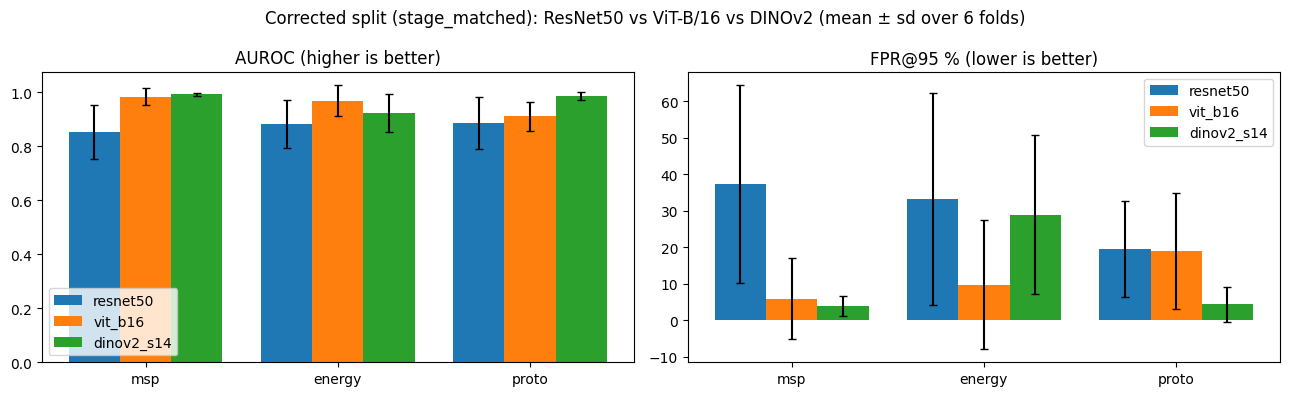

In [6]:
summ = (res.groupby(["backbone", "protocol", "method"])
          .agg(AUROC_mean=("AUROC", "mean"), AUROC_std=("AUROC", "std"),
               FPR95_mean=("FPR95", "mean"), test_FRR_at_val_thr=("test_false_reject_at_val_thr", "mean"),
               test_FRR_fresh=("test_FRR_fresh", "mean"), test_FRR_spoiled=("test_FRR_spoiled", "mean"),
               AUROC_vs_fresh_known=("AUROC_vs_fresh_known", "mean"), AUROC_vs_spoiled_known=("AUROC_vs_spoiled_known", "mean"))
          .reset_index())
for c in ["FPR95_mean", "test_FRR_at_val_thr", "test_FRR_fresh", "test_FRR_spoiled"]:
    summ[c] *= 100
display(summ.round(4))
summ.to_csv(OUT / "summary_by_backbone.csv", index=False)
display(acc.groupby(["backbone", "protocol"])[["val_acc", "test_acc"]].mean().round(4))

# put ResNet50 next to the transformers when the leakage notebook output is attached
rn = [h for h in glob.glob("/kaggle/input/**/ood_eval_per_fold.csv", recursive=True) if "transformers" not in h]
if rn:
    r50 = pd.read_csv(rn[0]); r50["backbone"] = "resnet50"
    if "split_mode" in r50.columns and (r50[r50.protocol == "corrected"].split_mode != SPLIT_MODE).any():
        print("WARNING: attached ResNet50 results use a different split mode:", r50.split_mode.unique())
    allres = pd.concat([r50, res], ignore_index=True)
else:
    allres = res
    print("(leakage notebook output not attached: table below is transformers only)")
table = allres.pivot_table(index=["backbone", "method"], columns="protocol", values=["AUROC", "FPR95"], aggfunc="mean")
display(table.round(4))
table.to_csv(OUT / "all_backbones_old_vs_corrected.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bbs = list(allres.backbone.unique())
for ax, metric in zip(axes, ["AUROC", "FPR95"]):
    t = allres[allres.protocol == "corrected"].groupby(["backbone", "method"])[metric].agg(["mean", "std"]).reset_index()
    methods = ["msp", "energy", "proto"]; x = np.arange(len(methods)); wb = 0.8 / len(bbs)
    for i, b in enumerate(bbs):
        tt = t[t.backbone == b].set_index("method").reindex(methods)
        sc = 100 if metric == "FPR95" else 1
        ax.bar(x + (i - (len(bbs) - 1) / 2) * wb, tt["mean"] * sc, wb, yerr=tt["std"] * sc, capsize=3, label=b)
    ax.set_xticks(x); ax.set_xticklabels(methods); ax.legend()
    ax.set_title("AUROC (higher is better)" if metric == "AUROC" else "FPR@95 % (lower is better)")
plt.suptitle(f"Corrected split ({SPLIT_MODE}): ResNet50 vs ViT-B/16 vs DINOv2 (mean ± sd over 6 folds)")
plt.tight_layout(); plt.savefig(OUT / "backbones_corrected.png", dpi=200); plt.show()

In [7]:
for f in OUT.glob("embeddings_*.pt"):
    f.unlink()                      # embeddings are large and quick to recompute; keep heads + CSVs only
shutil.make_archive(str(OUT), "zip", OUT)
print("Download:", str(OUT) + ".zip")

Download: /kaggle/working/sentragrade_transformers.zip
